In [1]:
#202431055_Muhammad Rafi Kurniawan
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score

print("Semua library berhasil di-import")

Semua library berhasil di-import


In [2]:
#202431055_Muhammad Rafi Kurniawan
try:
    df = pd.read_csv('heart.csv')
except FileNotFoundError:
    from google.colab import files
    files.upload()
    df = pd.read_csv('heart.csv')

print("Jumlah baris x kolom :", df.shape[0], "x", df.shape[1])
df.head()

Jumlah baris x kolom : 918 x 12


,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138,214,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150,195,0,Normal,122,N,0.0,Up,0


In [3]:
#202431055_Muhammad Rafi Kurniawan
print("=== INFORMASI DATA ===")
df.info()

=== INFORMASI DATA ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 918 entries, 0 to 917
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Age             918 non-null    int64  
 1   Sex             918 non-null    object 
 2   ChestPainType   918 non-null    object 
 3   RestingBP       918 non-null    int64  
 4   Cholesterol     918 non-null    int64  
 5   FastingBS       918 non-null    int64  
 6   RestingECG      918 non-null    object 
 7   MaxHR           918 non-null    int64  
 8   ExerciseAngina  918 non-null    object 
 9   Oldpeak         918 non-null    float64
 10  ST_Slope        918 non-null    object 
 11  HeartDisease    918 non-null    int64  
dtypes: float64(1), int64(6), object(5)
memory usage: 86.2+ KB


In [4]:
#202431055_Muhammad Rafi Kurniawan
print("=== DESKRIPSI STATISTIK ===")
display(df.describe())

print("\n=== CEK MISSING VALUE ===")
print(df.isnull().sum())

=== DESKRIPSI STATISTIK ===


,Age,RestingBP,Cholesterol,FastingBS,MaxHR,Oldpeak,HeartDisease
count,918.000000,918.000000,918.000000,918.000000,918.000000,918.000000,918.000000
mean,53.510893,132.396514,198.799564,0.233115,136.809368,0.887364,0.553377
std,9.432617,18.514154,109.384145,0.423046,25.460334,1.066570,0.497414
min,28.000000,0.000000,0.000000,0.000000,60.000000,-2.600000,0.000000
25%,47.000000,120.000000,173.250000,0.000000,120.000000,0.000000,0.000000
50%,54.000000,130.000000,223.000000,0.000000,138.000000,0.600000,1.000000
75%,60.000000,140.000000,267.000000,0.000000,156.000000,1.500000,1.000000
max,77.000000,200.000000,603.000000,1.000000,202.000000,6.200000,1.000000



=== CEK MISSING VALUE ===
Age               0
Sex               0
ChestPainType     0
RestingBP         0
Cholesterol       0
FastingBS         0
RestingECG        0
MaxHR             0
ExerciseAngina    0
Oldpeak           0
ST_Slope          0
HeartDisease      0
dtype: int64


In [5]:
#202431055_Muhammad Rafi Kurniawan
target = 'HeartDisease'

fitur_numerik = df.select_dtypes(include='number').columns.drop(target).tolist()

print("Jumlah fitur numerik :", len(fitur_numerik))
print("Daftar fitur numerik :", fitur_numerik)

Jumlah fitur numerik : 6
Daftar fitur numerik : ['Age', 'RestingBP', 'Cholesterol', 'FastingBS', 'MaxHR', 'Oldpeak']


In [6]:
#202431055_Muhammad Rafi Kurniawan
fitur_kategorikal = df.select_dtypes(exclude='number').columns.tolist()

print("Jumlah fitur kategorikal :", len(fitur_kategorikal))
print("Daftar fitur kategorikal :", fitur_kategorikal)

Jumlah fitur kategorikal : 5
Daftar fitur kategorikal : ['Sex', 'ChestPainType', 'RestingECG', 'ExerciseAngina', 'ST_Slope']


In [7]:
#202431055_Muhammad Rafi Kurniawan
for kolom in fitur_kategorikal:
    print(f"{kolom:15s}: {df[kolom].unique().tolist()}")

Sex            : ['M', 'F']
ChestPainType  : ['ATA', 'NAP', 'ASY', 'TA']
RestingECG     : ['Normal', 'ST', 'LVH']
ExerciseAngina : ['N', 'Y']
ST_Slope       : ['Up', 'Flat', 'Down']


In [8]:
#202431055_Muhammad Rafi Kurniawan
df_encoded = df.copy()
encoders = {}

for kolom in fitur_kategorikal:
    le = LabelEncoder()
    df_encoded[kolom] = le.fit_transform(df_encoded[kolom])
    encoders[kolom] = le
    # tampilkan pemetaan kategori -> angka
    pemetaan = {k: int(v) for v, k in enumerate(le.classes_)}
    print(f"{kolom:15s}: {pemetaan}")

print("\nHasil setelah LabelEncoder:")
df_encoded.head()

Sex            : {'F': 0, 'M': 1}
ChestPainType  : {'ASY': 0, 'ATA': 1, 'NAP': 2, 'TA': 3}
RestingECG     : {'LVH': 0, 'Normal': 1, 'ST': 2}
ExerciseAngina : {'N': 0, 'Y': 1}
ST_Slope       : {'Down': 0, 'Flat': 1, 'Up': 2}

Hasil setelah LabelEncoder:


,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,1,1,140,289,0,1,172,0,0.0,2,0
1,49,0,2,160,180,0,1,156,0,1.0,1,1
2,37,1,1,130,283,0,2,98,0,0.0,2,0
3,48,0,0,138,214,0,1,108,1,1.5,1,1
4,54,1,2,150,195,0,1,122,0,0.0,2,0


In [9]:
#202431055_Muhammad Rafi Kurniawan
x = df_encoded.drop(columns=[target])
y = df_encoded[target]

print("Bentuk x :", x.shape)
print("Bentuk y :", y.shape)
print("\nSebaran kelas target:")
print(y.value_counts())

Bentuk x : (918, 11)
Bentuk y : (918,)

Sebaran kelas target:
1    508
0    410
Name: HeartDisease, dtype: int64


In [10]:
#202431055_Muhammad Rafi Kurniawan
x_train, x_test, y_train, y_test = train_test_split(
    x, y, test_size=0.25, random_state=0
)

print("Data latih :", x_train.shape[0], "baris")
print("Data uji   :", x_test.shape[0], "baris")

Data latih : 688 baris
Data uji   : 230 baris


In [11]:
#202431055_Muhammad Rafi Kurniawan
model = GaussianNB()
model.fit(x_train, y_train)

print("Model GaussianNB berhasil dilatih")
print("Kelas yang dikenali model :", model.classes_)
print("Prior tiap kelas          :", model.class_prior_.round(4))

Model GaussianNB berhasil dilatih
Kelas yang dikenali model : [0 1]
Prior tiap kelas          : [0.4622 0.5378]


In [12]:
#202431055_Muhammad Rafi Kurniawan
y_pred_train = model.predict(x_train)
y_pred_test  = model.predict(x_test)

print("5 prediksi data latih :", y_pred_train[:5])
print("5 prediksi data uji   :", y_pred_test[:5])

5 prediksi data latih : [0 1 1 1 0]
5 prediksi data uji   : [1 0 1 1 0]


Evaluasi Training
Confusion Matrix:
[[274  44]
 [ 51 319]]

Classification Report:
              precision    recall  f1-score   support

           0       0.84      0.86      0.85       318
           1       0.88      0.86      0.87       370

    accuracy                           0.86       688
   macro avg       0.86      0.86      0.86       688
weighted avg       0.86      0.86      0.86       688



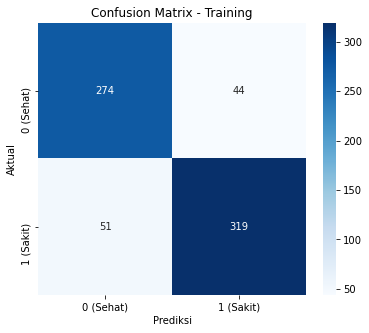

In [13]:
#202431055_Muhammad Rafi Kurniawan
print("=" * 50)
print("Evaluasi Training")
print("=" * 50)

cm_train = confusion_matrix(y_train, y_pred_train)
print("Confusion Matrix:")
print(cm_train)

print("\nClassification Report:")
print(classification_report(y_train, y_pred_train))

plt.figure(figsize=(6, 5))
sns.heatmap(cm_train, annot=True, fmt='d', cmap='Blues',
            xticklabels=['0 (Sehat)', '1 (Sakit)'],
            yticklabels=['0 (Sehat)', '1 (Sakit)'])
plt.title("Confusion Matrix - Training")
plt.xlabel("Prediksi")
plt.ylabel("Aktual")
plt.show()

Evaluasi Testing
Confusion Matrix:
[[ 73  19]
 [ 16 122]]

Classification Report:
              precision    recall  f1-score   support

           0       0.82      0.79      0.81        92
           1       0.87      0.88      0.87       138

    accuracy                           0.85       230
   macro avg       0.84      0.84      0.84       230
weighted avg       0.85      0.85      0.85       230



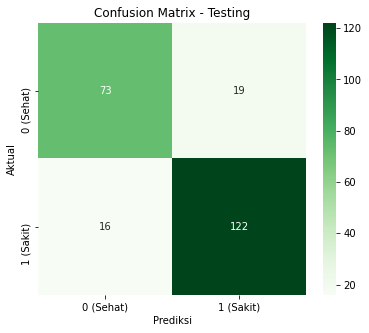

In [14]:
#202431055_Muhammad Rafi Kurniawan
print("=" * 50)
print("Evaluasi Testing")
print("=" * 50)

cm_test = confusion_matrix(y_test, y_pred_test)
print("Confusion Matrix:")
print(cm_test)

print("\nClassification Report:")
print(classification_report(y_test, y_pred_test))

plt.figure(figsize=(6, 5))
sns.heatmap(cm_test, annot=True, fmt='d', cmap='Greens',
            xticklabels=['0 (Sehat)', '1 (Sakit)'],
            yticklabels=['0 (Sehat)', '1 (Sakit)'])
plt.title("Confusion Matrix - Testing")
plt.xlabel("Prediksi")
plt.ylabel("Aktual")
plt.show()

In [15]:
#202431055_Muhammad Rafi Kurniawan
data_baru = pd.DataFrame([{
    'Age': 55,
    'Sex': 'M',
    'ChestPainType': 'ASY',
    'RestingBP': 140,
    'Cholesterol': 220,
    'FastingBS': 0,
    'RestingECG': 'Normal',
    'MaxHR': 120,
    'ExerciseAngina': 'Y',
    'Oldpeak': 1.5,
    'ST_Slope': 'Flat'
}])
print("Data baru (sebelum encoding):")
display(data_baru)

data_baru_enc = data_baru.copy()
for kolom in fitur_kategorikal:
    data_baru_enc[kolom] = encoders[kolom].transform(data_baru_enc[kolom])

data_baru_enc = data_baru_enc[x.columns]
print("\nData baru (setelah encoding):")
display(data_baru_enc)

hasil = model.predict(data_baru_enc)[0]
proba = model.predict_proba(data_baru_enc)[0]

keterangan = {0: "TIDAK ada penyakit jantung", 1: "ADA penyakit jantung"}
print("\n=== HASIL PREDIKSI DATA BARU ===")
print("Kelas prediksi   :", hasil)
print("Artinya          :", keterangan[hasil])
print(f"Peluang kelas 0  : {proba[0]:.4f}")
print(f"Peluang kelas 1  : {proba[1]:.4f}")

Data baru (sebelum encoding):


,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope
0,55,M,ASY,140,220,0,Normal,120,Y,1.5,Flat



Data baru (setelah encoding):


,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope
0,55,1,0,140,220,0,1,120,1,1.5,1



=== HASIL PREDIKSI DATA BARU ===
Kelas prediksi   : 1
Artinya          : ADA penyakit jantung
Peluang kelas 0  : 0.0044
Peluang kelas 1  : 0.9956
